In [2]:
import os
import zipfile
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU devices:", gpus if gpus else "No GPU detected; running on CPU.")

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [3]:
import os
from pathlib import Path

# On Kaggle the dataset is already unzipped under /kaggle/input
# (add it from the right sidebar: Add Input -> search the brain tumor MRI dataset).
KAGGLE_INPUT = Path("/kaggle/input")

if not KAGGLE_INPUT.is_dir():
    raise EnvironmentError("This code is for Kaggle notebooks (/kaggle/input not found).")

# Find the real dataset root, even if the dataset has an extra parent folder.
training_dirs = sorted(
    p for p in KAGGLE_INPUT.rglob("*")
    if p.is_dir() and p.name.lower() == "training"
)
if not training_dirs:
    raise FileNotFoundError(
        "A 'Training' folder was not found under /kaggle/input. "
        "Click 'Add Input' and add the brain tumor dataset to this notebook."
    )

DATA_ROOT = training_dirs[0].parent
TRAIN_DIR = DATA_ROOT / "Training"

# Accept 'Testing' / 'testing' / 'Test'
test_candidates = [p for p in DATA_ROOT.iterdir()
                   if p.is_dir() and p.name.lower() in ("testing", "test")]
if not test_candidates:
    raise FileNotFoundError(f"Expected a Testing folder inside: {DATA_ROOT}")
TEST_DIR = test_candidates[0]

# Kaggle input is read-only, so anything you save must go to /kaggle/working
OUTPUT_DIR = Path("/kaggle/working")

print("Dataset root   :", DATA_ROOT)
print("Training folder:", TRAIN_DIR)
print("Testing folder :", TEST_DIR)

# Quick check: classes and image counts per folder
for split_dir in (TRAIN_DIR, TEST_DIR):
    print(f"\n{split_dir.name}:")
    for cls in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        n = sum(1 for f in cls.iterdir() if f.suffix.lower() in (".jpg", ".jpeg", ".png"))
        print(f"  {cls.name:<12} {n} images")

Dataset root   : /kaggle/input/datasets/abdullahalaminifaz/tumor-classification-data
Training folder: /kaggle/input/datasets/abdullahalaminifaz/tumor-classification-data/Training
Testing folder : /kaggle/input/datasets/abdullahalaminifaz/tumor-classification-data/Testing

Training:
  glioma       1400 images
  meningioma   1400 images
  notumor      1400 images
  pituitary    1400 images

Testing:
  glioma       400 images
  meningioma   400 images
  notumor      400 images
  pituitary    400 images


In [4]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

class_names = sorted(
    p.name for p in TRAIN_DIR.iterdir()
    if p.is_dir()
)
print("Classes:", class_names)

def collect_image_records(folder):
    records = []
    for class_name in class_names:
        class_dir = folder / class_name
        if not class_dir.is_dir():
            print(f"Warning: missing class folder: {class_dir}")
            continue
        for image_path in class_dir.rglob("*"):
            if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
                records.append({
                    "filepath": str(image_path),
                    "label": class_name
                })
    return pd.DataFrame(records)

train_records = collect_image_records(TRAIN_DIR)
test_records = collect_image_records(TEST_DIR)

if train_records.empty:
    raise ValueError("No training images found. Check the dataset folder structure.")

print("Training images:", len(train_records))
print("Testing images:", len(test_records))
display(train_records.groupby("label").size().rename("training_count").to_frame())
display(test_records.groupby("label").size().rename("testing_count").to_frame())

# Verify that every image path exists and every label belongs to a known class.
assert train_records["filepath"].map(os.path.isfile).all()
assert set(train_records["label"].unique()).issubset(set(class_names))

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Training images: 5600
Testing images: 1600


,training_count
label,
glioma,1400
meningioma,1400
notumor,1400
pituitary,1400


,testing_count
label,
glioma,400
meningioma,400
notumor,400
pituitary,400


In [5]:
train_df, val_df = train_test_split(
    train_records,
    test_size=0.20,
    random_state=SEED,
    stratify=train_records["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("\nTraining label distribution:")
print(train_df["label"].value_counts())
print("\nValidation label distribution:")
print(val_df["label"].value_counts())

class_to_index = {name: index for index, name in enumerate(class_names)}
index_to_class = {index: name for name, index in class_to_index.items()}

Training samples: 4480
Validation samples: 1120

Training label distribution:
label
pituitary     1120
notumor       1120
glioma        1120
meningioma    1120
Name: count, dtype: int64

Validation label distribution:
label
glioma        280
meningioma    280
pituitary     280
notumor       280
Name: count, dtype: int64


In [6]:
IMG_SIZE = (299, 299)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
NUM_CLASSES = len(class_names)

def decode_and_resize(filepath, label):
    image = tf.io.read_file(filepath)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, label

def dataframe_to_dataset(dataframe, shuffle=False):
    paths = dataframe["filepath"].values
    labels = dataframe["label"].map(class_to_index).values.astype("int32")
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )
    ds = ds.map(decode_and_resize, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = dataframe_to_dataset(train_df, shuffle=True)
val_ds = dataframe_to_dataset(val_df, shuffle=False)

for images, labels in train_ds.take(1):
    print("Image batch:", images.shape)
    print("Label batch:", labels.shape)

Image batch: (32, 299, 299, 3)
Label batch: (32,)


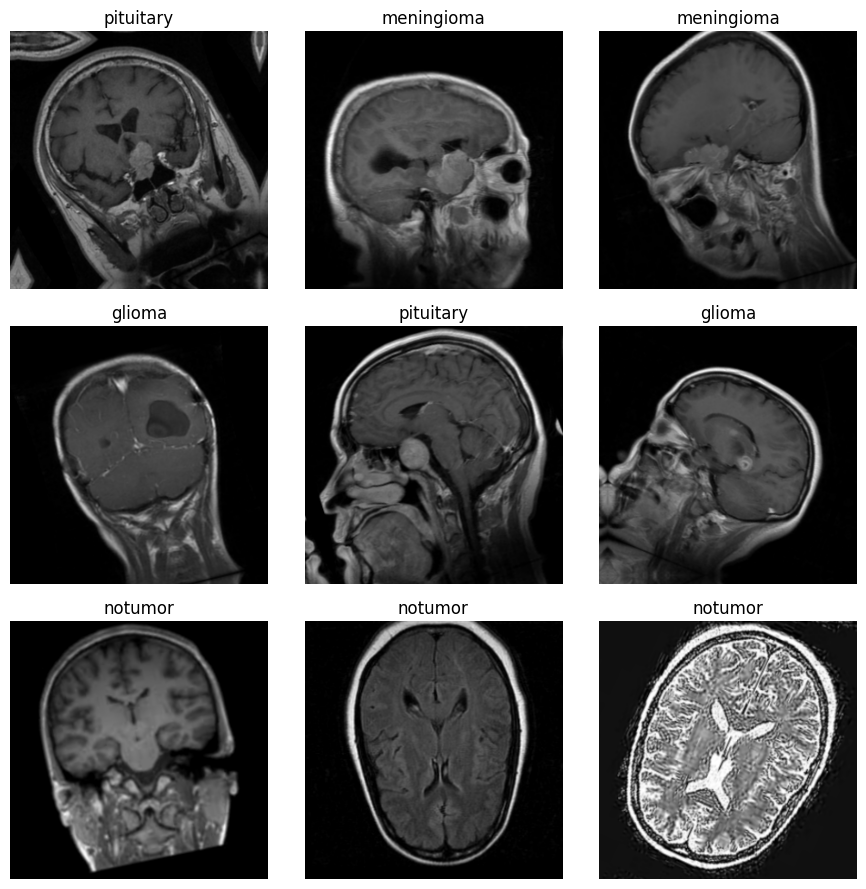

In [7]:
data_augmentation = tf.keras.Sequential(
    [
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.08),
        tf.keras.layers.RandomZoom(0.10),
        tf.keras.layers.RandomContrast(0.10),
    ],
    name="data_augmentation"
)

# Preview a few augmented training images.
for images, labels in train_ds.take(1):
    augmented_images = data_augmentation(images[:9], training=True)
    plt.figure(figsize=(9, 9))
    for i in range(min(9, len(augmented_images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(tf.cast(tf.clip_by_value(augmented_images[i], 0, 255), tf.uint8))
        plt.title(index_to_class[int(labels[i].numpy())])
        plt.axis("off")
    plt.tight_layout()
    plt.show()

In [8]:
from tensorflow.keras.applications.inception_v3 import InceptionV3, preprocess_input

LOCAL_WEIGHTS_PATH = None  # Example: "/content/inception_v3_weights_tf_dim_ordering_tf_kernels_notop.h5"

base_model = None
weights_source = None

if LOCAL_WEIGHTS_PATH and os.path.isfile(LOCAL_WEIGHTS_PATH):
    try:
        base_model = InceptionV3(
            include_top=False, weights=LOCAL_WEIGHTS_PATH,
            input_shape=(*IMG_SIZE, 3)
        )
        weights_source = "local weights file"
    except Exception as e:
        print("Local weights could not be loaded:", repr(e))

if base_model is None:
    try:
        base_model = InceptionV3(
            include_top=False, weights="imagenet",
            input_shape=(*IMG_SIZE, 3)
        )
        weights_source = "ImageNet pretrained weights"
    except Exception as e:
        print("Could not load ImageNet weights; using offline fallback.")
        print("Reason:", repr(e))
        base_model = InceptionV3(
            include_top=False, weights=None,
            input_shape=(*IMG_SIZE, 3)
        )
        weights_source = "random initialization (offline fallback)"

print("InceptionV3 weights:", weights_source)

base_model.trainable = False

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3), name="input_image")
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.35)(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)

model = tf.keras.Model(inputs, outputs, name="inceptionv3_brain_tumor_classifier")
model.summary()

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
InceptionV3 weights: ImageNet pretrained weights


Model: "inceptionv3_brain_tumor_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 8, 8, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,810,980 (83.20 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 21,802,784 (83.17 MB)

In [9]:
MODEL_DIR = Path("model_output")
MODEL_DIR.mkdir(exist_ok=True)

checkpoint_path = MODEL_DIR / "best_inceptionv3.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

In [10]:
EPOCHS_PHASE_1 = 10

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_phase1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE_1,
    callbacks=callbacks
)

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 527ms/step - accuracy: 0.5907 - loss: 0.9533
Epoch 1: val_loss improved from None to 0.52149, saving model to model_output/best_inceptionv3.keras

Epoch 1: finished saving model to model_output/best_inceptionv3.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 107s 692ms/step - accuracy: 0.7049 - loss: 0.7344 - val_accuracy: 0.8062 - val_loss: 0.5215 - learning_rate: 0.0010
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - accuracy: 0.8210 - loss: 0.4875
Epoch 2: val_loss improved from 0.52149 to 0.42460, saving model to model_output/best_inceptionv3.keras

Epoch 2: finished saving model to model_output/best_inceptionv3.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 32s 230ms/step - accuracy: 0.8246 - loss: 0.4796 - val_accuracy: 0.8473 - val_loss: 0.4246 - learning_rate: 0.0010
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - accuracy: 0.8257 - loss: 0.4562
Epoch 3: val_loss improved from 0.42460 to 0.37987, saving model to model_output/best_inceptionv3.ke

In [11]:
base_model.trainable = True

# Fine-tune only the later layers.
FINE_TUNE_FROM = int(len(base_model.layers) * 0.70)
for layer in base_model.layers[:FINE_TUNE_FROM]:
    layer.trainable = False
for layer in base_model.layers[FINE_TUNE_FROM:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

EPOCHS_PHASE_2 = 10
history_phase2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE_2,
    callbacks=callbacks
)

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step - accuracy: 0.8817 - loss: 0.3127
Epoch 1: val_loss improved from 0.32477 to 0.28400, saving model to model_output/best_inceptionv3.keras

Epoch 1: finished saving model to model_output/best_inceptionv3.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 54s 305ms/step - accuracy: 0.8839 - loss: 0.3073 - val_accuracy: 0.8920 - val_loss: 0.2840 - learning_rate: 1.0000e-05
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step - accuracy: 0.9170 - loss: 0.2300
Epoch 2: val_loss improved from 0.28400 to 0.25125, saving model to model_output/best_inceptionv3.keras

Epoch 2: finished saving model to model_output/best_inceptionv3.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 39s 276ms/step - accuracy: 0.9154 - loss: 0.2315 - val_accuracy: 0.9080 - val_loss: 0.2513 - learning_rate: 1.0000e-05
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 228ms/step - accuracy: 0.9327 - loss: 0.1940
Epoch 3: val_loss improved from 0.25125 to 0.19028, saving model to model_output/best_ince

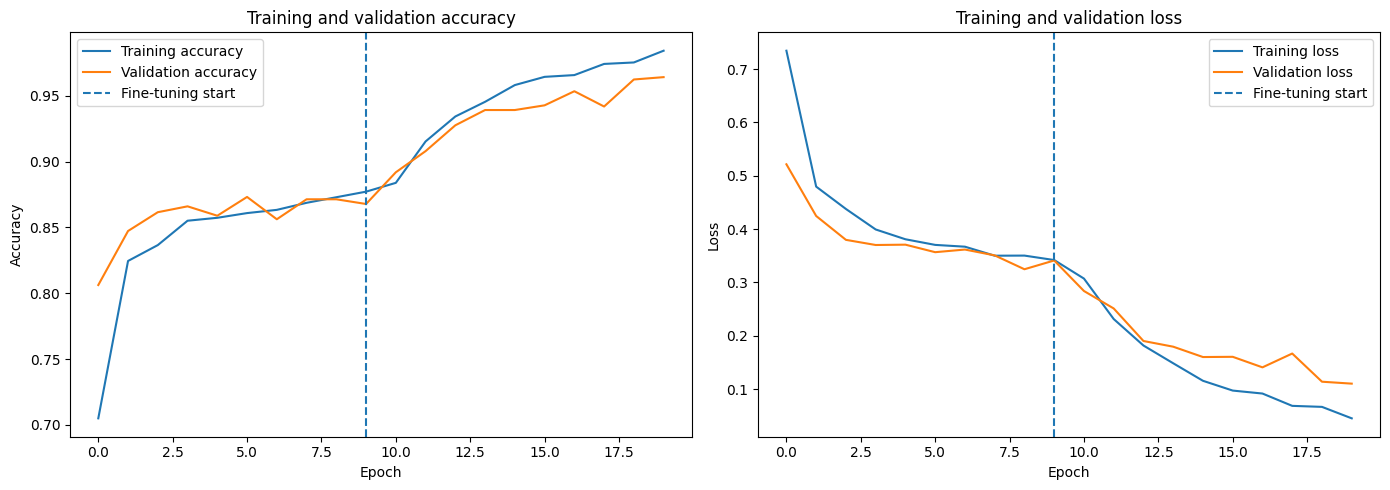

In [12]:
def combine_histories(*histories):
    combined = {}
    for history in histories:
        for key, values in history.history.items():
            combined.setdefault(key, []).extend(values)
    return combined

history_all = combine_histories(history_phase1, history_phase2)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(history_all["accuracy"], label="Training accuracy")
plt.plot(history_all["val_accuracy"], label="Validation accuracy")
plt.axvline(len(history_phase1.history["accuracy"]) - 1, linestyle="--", label="Fine-tuning start")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and validation accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_all["loss"], label="Training loss")
plt.plot(history_all["val_loss"], label="Validation loss")
plt.axvline(len(history_phase1.history["loss"]) - 1, linestyle="--", label="Fine-tuning start")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and validation loss")
plt.legend()
plt.tight_layout()
plt.show()

50/50 ━━━━━━━━━━━━━━━━━━━━ 30s 596ms/step - accuracy: 0.9306 - loss: 0.3999
Test loss: 0.3999
Test accuracy: 0.9306
50/50 ━━━━━━━━━━━━━━━━━━━━ 10s 167ms/step

Classification report:
              precision    recall  f1-score   support

      glioma       0.97      0.80      0.88       400
  meningioma       0.89      0.94      0.91       400
     notumor       0.91      1.00      0.95       400
   pituitary       0.97      0.98      0.98       400

    accuracy                           0.93      1600
   macro avg       0.93      0.93      0.93      1600
weighted avg       0.93      0.93      0.93      1600



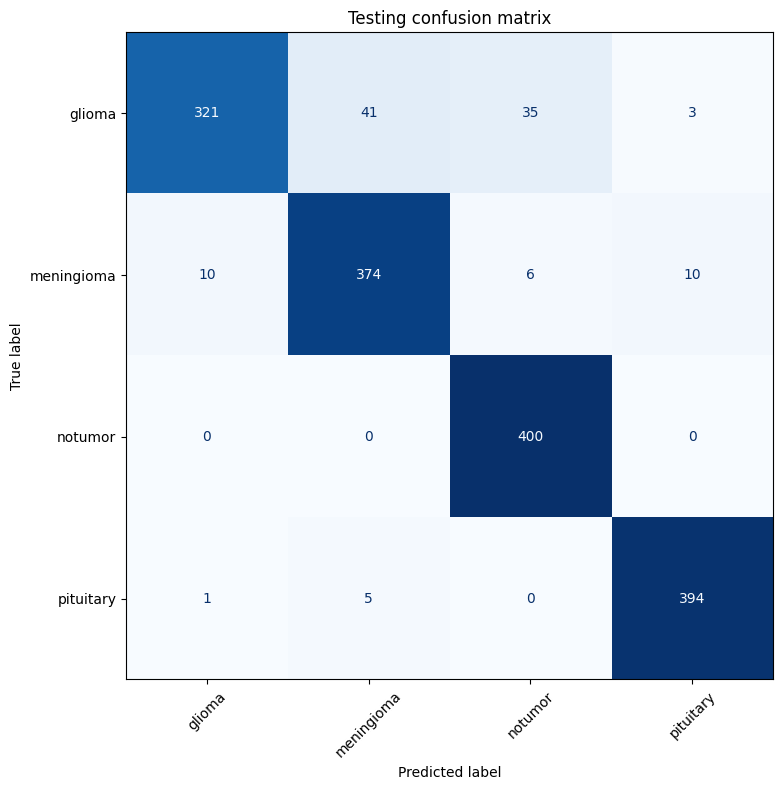

In [13]:
# Evaluate on the held-out Testing folder.
def test_dataframe_to_dataset(dataframe):
    paths = dataframe["filepath"].values
    labels = dataframe["label"].map(class_to_index).values.astype("int32")
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(decode_and_resize, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

test_ds = test_dataframe_to_dataset(test_records)

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

y_true = test_records["label"].map(class_to_index).values
probabilities = model.predict(test_ds, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

print("\nClassification report:")
print(classification_report(
    y_true, y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(8, 8))
display.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title("Testing confusion matrix")
plt.tight_layout()
plt.show()

In [14]:
from IPython.display import display as notebook_display
from PIL import Image

def predict_one_image(image_path, trained_model=model):
    image = tf.keras.utils.load_img(image_path, target_size=IMG_SIZE)
    image_array = tf.keras.utils.img_to_array(image)
    batch = np.expand_dims(image_array, axis=0)

    probs = trained_model.predict(batch, verbose=0)[0]
    predicted_index = int(np.argmax(probs))

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"Prediction: {index_to_class[predicted_index]} "
        f"({probs[predicted_index] * 100:.2f}%)"
    )
    plt.show()

    return pd.DataFrame({
        "class": class_names,
        "probability": probs
    }).sort_values("probability", ascending=False).reset_index(drop=True)

# Set this to the path of a separate image you want to test.
NEW_IMAGE_PATH = None  # Example: "/content/my_brain_scan.jpg"

if NEW_IMAGE_PATH and os.path.isfile(NEW_IMAGE_PATH):
    display(predict_one_image(NEW_IMAGE_PATH))
else:
    print("Set NEW_IMAGE_PATH to an image file path to run a single-image prediction.")

Set NEW_IMAGE_PATH to an image file path to run a single-image prediction.


In [18]:
from pathlib import Path
import numpy as np
import tensorflow as tf
from IPython.display import display   # restores display() if a variable overwrote it

# Output folder (keeps your MODEL_DIR if it exists; otherwise uses Kaggle's writable folder)
MODEL_DIR = Path(globals().get("MODEL_DIR", "/kaggle/working"))
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# ---- Build the dataset for the whole testing folder ----
all_test_paths = [str(p) for p in test_records["filepath"]]

def load_for_prediction(path):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    return image

all_test_images = (
    tf.data.Dataset.from_tensor_slices(all_test_paths)
    .map(load_for_prediction, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# ---- Predict ----
all_probabilities = model.predict(all_test_images, verbose=1)
all_predicted_indices = np.argmax(all_probabilities, axis=1)
all_confidences = np.max(all_probabilities, axis=1)

whole_test_predictions = test_records.copy()
whole_test_predictions["predicted_label"] = [index_to_class[i] for i in all_predicted_indices]
whole_test_predictions["confidence"] = all_confidences
whole_test_predictions["correct"] = (
    whole_test_predictions["label"] == whole_test_predictions["predicted_label"]
)

# ---- Save and report ----
PREDICTIONS_CSV = MODEL_DIR / "whole_testing_folder_predictions.csv"
whole_test_predictions.to_csv(PREDICTIONS_CSV, index=False)

display(whole_test_predictions.head(20))
print("Total images predicted:", len(whole_test_predictions))
print("Correct predictions   :", int(whole_test_predictions["correct"].sum()))
print(f"Prediction accuracy   : {whole_test_predictions['correct'].mean():.4f}")
print("Saved predictions to  :", PREDICTIONS_CSV.resolve())

50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 174ms/step


,filepath,label,predicted_label,confidence,correct
0,/kaggle/input/datasets/abdullahalaminifaz/tumo...,glioma,meningioma,0.545176,False
1,/kaggle/input/datasets/abdullahalaminifaz/tumo...,glioma,glioma,0.999997,True
2,/kaggle/input/datasets/abdullahalaminifaz/tumo...,glioma,glioma,1.000000,True
3,/kaggle/input/datasets/abdullahalaminifaz/tumo...,glioma,meningioma,0.890335,False
4,/kaggle/input/datasets/abdullahalaminifaz/tumo...,glioma,notumor,0.642977,False
5,/kaggle/input/datasets/abdullahalaminifaz/tumo...,glioma,glioma,0.956493,True
6,/kaggle/input/datasets/abdullahalaminifaz/tumo...,glioma,glioma,0.983617,True
7,/kaggle/input/datasets/abdullahalaminifaz/tumo...,glioma,glioma,0.999989,True
8,/kaggle/input/datasets/abdullahalaminifaz/tumo...,glioma,meningioma,0.999461,False
9,/kaggle/input/datasets/abdullahalaminifaz/tumo...,glioma,glioma,0.993031,True


Total images predicted: 1600
Correct predictions   : 1489
Prediction accuracy   : 0.9306
Saved predictions to  : /kaggle/working/model_output/whole_testing_folder_predictions.csv


In [19]:
def predict_folder(folder_path, output_csv="folder_predictions.csv"):
    folder_path = Path(folder_path)
    paths = sorted(
        str(p) for p in folder_path.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )
    if not paths:
        raise ValueError(f"No supported image files found in {folder_path}")

    dataset = tf.data.Dataset.from_tensor_slices(paths)
    dataset = dataset.map(load_for_prediction, num_parallel_calls=AUTOTUNE)
    dataset = dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

    probs = model.predict(dataset, verbose=1)
    pred_indices = np.argmax(probs, axis=1)

    results = pd.DataFrame({
        "filepath": paths,
        "predicted_label": [index_to_class[i] for i in pred_indices],
        "confidence": np.max(probs, axis=1)
    })
    results.to_csv(output_csv, index=False)
    return results

# Example:
# arbitrary_folder_results = predict_folder("/content/unlabelled_scans")
# display(arbitrary_folder_results.head())